In [ ]:
#importing library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

Part 1: Import Data

In [ ]:
# Importing dataset
data = pd.read_csv("/content/X_train.csv")
data2 = pd.read_csv("/content/y_train.csv")
data3 = pd.read_csv("/content/X_validation.csv")
data4 = pd.read_csv("/content/X_test.csv")

# Align training inputs and labels using the 'id' column
train_merged = pd.merge(data, data2, on='id', how='inner')

# Input training data from aligned dataframe
TRQ_meas = train_merged['trq_measured'].to_numpy()
OAT = train_merged['oat'].to_numpy()
MGT = train_merged['mgt'].to_numpy()
PA = train_merged['pa'].to_numpy()
IAS = train_merged['ias'].to_numpy()
NP = train_merged['np'].to_numpy()
NG = train_merged['ng'].to_numpy()

# Input validation data
TRQ_meas_valid = data3['trq_measured'].to_numpy()
OAT_valid = data3['oat'].to_numpy()
MGT_valid = data3['mgt'].to_numpy()
PA_valid = data3['pa'].to_numpy()
IAS_valid = data3['ias'].to_numpy()
NP_valid = data3['np'].to_numpy()
NG_valid = data3['ng'].to_numpy()

# Training output data
FAULTY = train_merged['faulty'].to_numpy()
TRQ_margin = train_merged['trq_margin'].to_numpy()
assert np.isin(FAULTY, [0,1]).all(), "FAULTY must be 0 or 1"

# Combining the data set
X_all = np.column_stack((TRQ_meas, OAT, MGT, PA, IAS, NP, NG))
Y_all = FAULTY.astype("int32")

features = ["trq_measured", "oat", "mgt","pa", "ias", "np", "ng"]

X_supplied_test = data4[features].to_numpy()

print("Original Train inputs rows:", len(data))
print("Original Train labels rows:", len(data2))
print("Aligned training rows:", len(train_merged))
print("Combined inputs:", X_all.shape)
print("Combined labels:", Y_all.shape)

assert len(X_all) == len(Y_all), \
    "Training inputs and labels must have the same number of rows"

Original Train inputs rows: 136503
Original Train labels rows: 78656
Aligned training rows: 78656
Combined inputs: (78656, 7)
Combined labels: (78656,)


Part 2: Data Preprocessing (Split + Standardizing)

In [ ]:
# Test train splitting (using the aligned X_all and Y_all)
X_train, X_test, Y_train, Y_test = train_test_split(X_all, Y_all, test_size=0.2, random_state=42, stratify=Y_all)

# replace missing values using training column medians
imputer = SimpleImputer(strategy='median')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Use valid features to construct X_valid
X_valid = np.column_stack((TRQ_meas_valid, OAT_valid, MGT_valid, PA_valid, IAS_valid, NP_valid, NG_valid))
X_valid = imputer.transform(X_valid)
X_supplied_test = imputer.transform(X_supplied_test)

# Training standardization
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)
std[std == 0] = 1 # prevent dividing by zero

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std
X_valid = (X_valid - mean) / std
X_supplied_test = (X_supplied_test - mean) / std

# TensorFlow inputs use float32.
X_train = X_train.astype("float32")
X_test = X_test.astype("float32")
X_valid = X_valid.astype("float32")
X_supplied_test = X_supplied_test.astype("float32")

print("Training shape:", X_train.shape)
print("Internal holdout shape:", X_test.shape)
print("Supplied validation shape:", X_valid.shape)
print("Supplied test shape:", X_supplied_test.shape)

Training shape: (62924, 7)
Internal holdout shape: (15732, 7)
Supplied validation shape: (21436, 7)
Supplied test shape: (21436, 7)


Part 3: Build and Compile ANN

In [ ]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,625 (10.25 KB)

 Trainable params: 2,625 (10.25 KB)

 Non-trainable params: 0 (0.00 B)

Part 4: Train the ANN

In [ ]:
history = model.fit(X_train, Y_train, epochs=50, validation_data=(X_test, Y_test), batch_size=64, shuffle=True, verbose=1)

Epoch 1/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9850 - loss: 0.0380 - val_accuracy: 0.9884 - val_loss: 0.0286
Epoch 2/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9858 - loss: 0.0364 - val_accuracy: 0.9875 - val_loss: 0.0287
Epoch 3/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9857 - loss: 0.0369 - val_accuracy: 0.9868 - val_loss: 0.0302
Epoch 4/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9863 - loss: 0.0360 - val_accuracy: 0.9886 - val_loss: 0.0274
Epoch 5/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9865 - loss: 0.0352 - val_accuracy: 0.9884 - val_loss: 0.0275
Epoch 6/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9861 - loss: 0.0364 - val_accuracy: 0.9893 - val_loss: 0.0262
Epoch 7/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9868 - loss: 0.0358 - val_accuracy: 0.9884 - val_loss: 0.0283
Epoch 8/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9865 - loss: 0.0355 - val_accuracy: 0.

Part 5: Plot Learning Curves

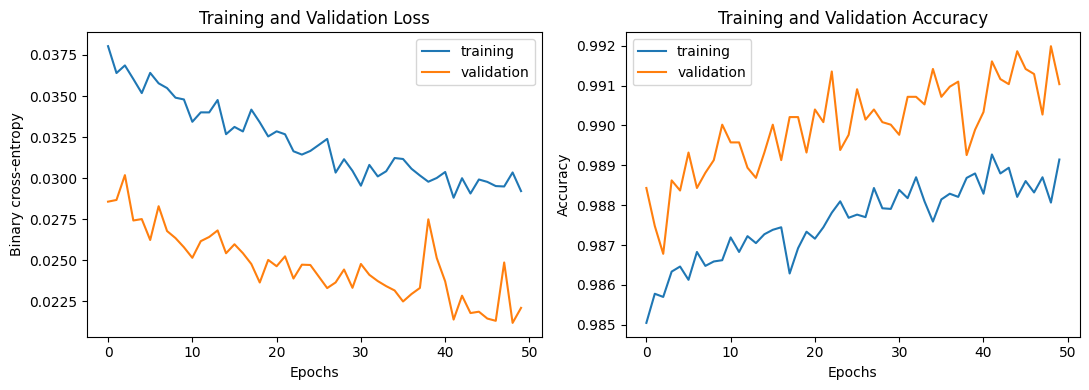

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(history.history[metric], label="training")
    ax.plot(history.history["val_"+metric], label="validation")
    ax.set_title("Training and Validation " + metric.capitalize())
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Binary cross-entropy" if metric == "loss" else "Accuracy")
    ax.legend()

plt.tight_layout()
plt.show()

Part 6: Evaluate Validation Performance